# Recommendation

<img src="https://www.pacificdataintegrators.com/hubfs/a-vibrant-retail-themed-illustration-with-a-deep-p-bal2vIl_StOKg4qpYTv6Wg-IcXSR6N_SxaaOyvOi4pBRg.jpeg" width=900>

### Dataset Download  
You can download the CSV file here:  
[https://amanxai.com/2021/03/23/amazon-recommendation-system-using-python/)

### Introduction
Recommender systems are widely used in e-commerce platforms to help users discover relevant products and improve the overall user experience.
In this project, an item-based recommendation system was developed using the Amazon Electronics ratings dataset.
Due to the large scale and high sparsity of the data, a sparse user–item matrix was constructed to efficiently model user–product interactions.
Cosine similarity was applied to identify similar products based on shared user ratings and generate personalized recommendations.

### Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from scipy import spatial
import joblib
import warnings
warnings.filterwarnings('ignore')

### Read Data

In [2]:
df1=pd.read_csv('ratings_Electronics (1).csv')

### EDA

In [3]:
df1.head()

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


In [4]:
df1.tail()

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
7824476,A2YZI3C9MOHC0L,BT008UKTMW,5.0,1396569600
7824477,A322MDK0M89RHN,BT008UKTMW,5.0,1313366400
7824478,A1MH90R0ADMIK0,BT008UKTMW,4.0,1404172800
7824479,A10M2KEFPEQDHN,BT008UKTMW,4.0,1297555200
7824480,A2G81TMIOIDEQQ,BT008V9J9U,5.0,1312675200


In [5]:
df1.shape

(7824481, 4)

In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column         Dtype  
---  ------         -----  
 0   AKM1MP6P0OYPR  object 
 1   0132793040     object 
 2   5.0            float64
 3   1365811200     int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 238.8+ MB


In [7]:
df1.isnull().sum()

AKM1MP6P0OYPR    0
0132793040       0
5.0              0
1365811200       0
dtype: int64

In [8]:
df1.columns=['user_id','product_id','rating','timestamp']

In [9]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   user_id     object 
 1   product_id  object 
 2   rating      float64
 3   timestamp   int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 238.8+ MB


In [10]:
df1['rating'].value_counts().sort_index()

rating
1.0     901765
2.0     456322
3.0     633073
4.0    1485781
5.0    4347540
Name: count, dtype: int64

In [11]:
df1['user_id'].nunique(), df1['product_id'].nunique()

(4201696, 476001)

In [12]:
df1.groupby('product_id')['rating'].count().describe()

count    476001.000000
mean         16.437951
std         112.702749
min           1.000000
25%           1.000000
50%           2.000000
75%           7.000000
max       18244.000000
Name: rating, dtype: float64

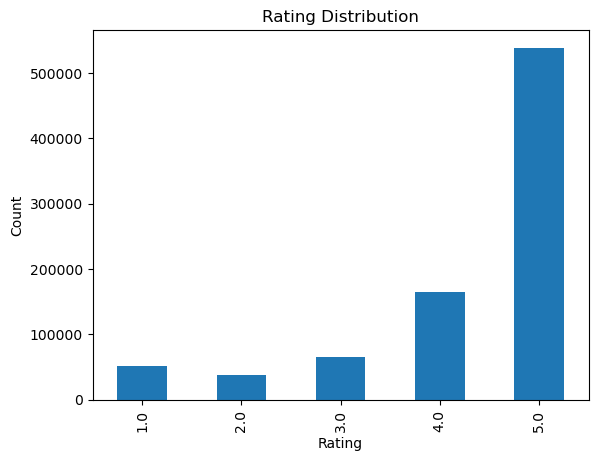

In [25]:
df["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

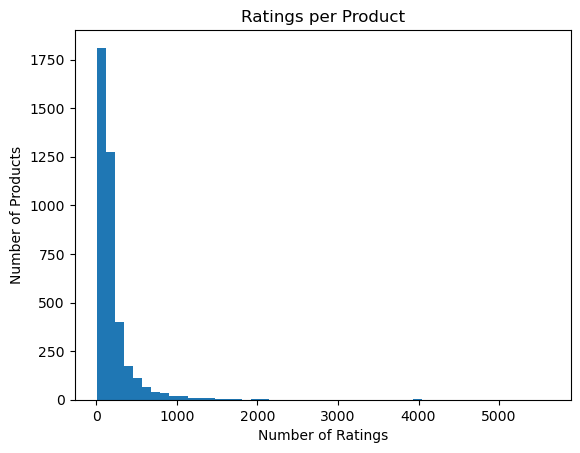

In [26]:
product=df.groupby("product_id").size()

plt.hist(product, bins=50)
plt.title("Ratings per Product")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Products")
plt.show()

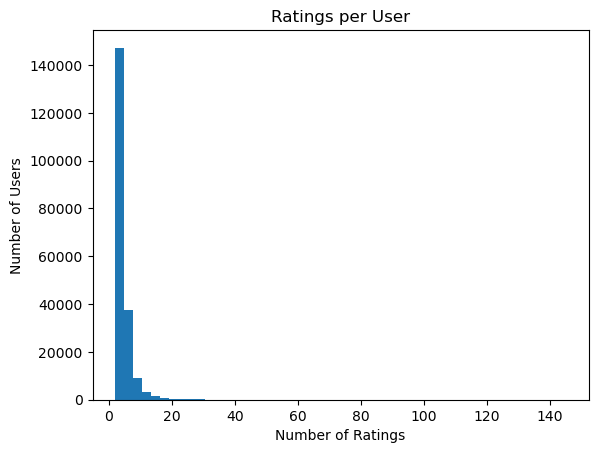

In [27]:
user=df.groupby("user_id").size()

plt.hist(user, bins=50)
plt.title("Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

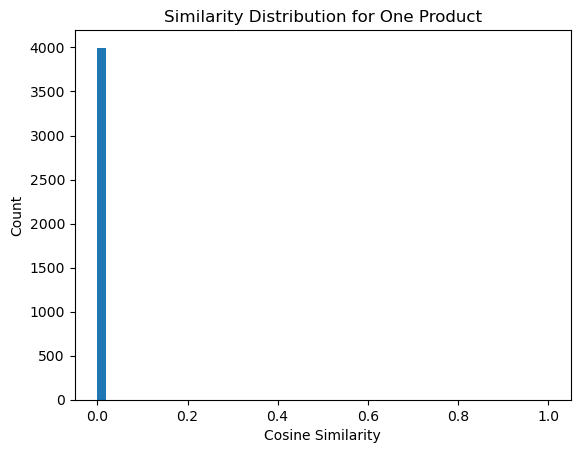

In [29]:
test_pid=product_ids[0]
j=prod_to_idx[test_pid]

item_vec=R[:, j].T
sims=cosine_similarity(item_vec, R.T).ravel()

plt.hist(sims, bins=50)
plt.title("Similarity Distribution for One Product")
plt.xlabel("Cosine Similarity")
plt.ylabel("Count")
plt.show()

In [28]:
num_users = R.shape[0]
num_items = R.shape[1]
num_interactions = R.nnz

sparsity = 1 - (num_interactions / (num_users * num_items))

print(f"Sparsity of the user-item matrix: {sparsity:.4f}")

Sparsity of the user-item matrix: 0.9989


In [16]:
top_item=4000
top_user=200000

top_items=(df1.groupby("product_id").size()
             .sort_values(ascending=False).head(top_item).index)

df_items=df1[df1["product_id"].isin(top_items)].copy()

top_users=(df_items.groupby("user_id").size()
             .sort_values(ascending=False).head(top_user).index)

df=df_items[df_items["user_id"].isin(top_users)].copy()

In [17]:
print("Rows:", df.shape)
print("Unique users:", df["user_id"].nunique())
print("Unique items:", df["product_id"].nunique())
print(df.groupby("product_id").size().describe())

Rows: (858212, 4)
Unique users: 200000
Unique items: 4000
count    4000.000000
mean      214.553000
std       300.158154
min        13.000000
25%        89.000000
50%       135.000000
75%       222.000000
max      5610.000000
dtype: float64


In [18]:
user_cat=pd.Categorical(df["user_id"])
item_cat=pd.Categorical(df["product_id"])
R=csr_matrix((df["rating"].astype(np.float32).values,(user_cat.codes, item_cat.codes)),shape=(len(user_cat.categories), len(item_cat.categories)))

product_ids=item_cat.categories
prod_to_idx={pid: i for i, pid in enumerate(product_ids)}

In [19]:
print("Sparse matrix shape:", R.shape)
print("Non-zeros:", R.nnz)

Sparse matrix shape: (200000, 4000)
Non-zeros: 858212


In [20]:
def recommend(product_id, top_n=10, min_sim=0.01):
    if product_id not in prod_to_idx:
        return pd.DataFrame({"message": ["Product not found."]})

    j=prod_to_idx[product_id]
    item_vec=R[:, j].T

    sims=cosine_similarity(item_vec, R.T).ravel()
    sims[j]=-1.0

    valid=np.where(sims >= min_sim)[0]
    top_idx=valid[np.argsort(sims[valid])[::-1][:top_n]]

    return pd.DataFrame({
        "recommended_product_id": product_ids[top_idx],
        "similarity": sims[top_idx].astype(float)
    })

In [21]:
test_pid=product_ids[0]
recommend(test_pid, top_n=10, min_sim=0.01)

,recommended_product_id,similarity
0,B000WYVBR0,0.023252
1,B0038KR8WM,0.021944
2,B003ES5ZUU,0.019811
3,B002BZFSYA,0.018440
4,B001GTT0VO,0.018127
5,B005D91G38,0.017495
6,B004GGNBJ6,0.015961
7,B000RT8CM2,0.015918
8,B009BVDV5A,0.015791
9,B004FJV8EE,0.014987


In [24]:
joblib.dump(R, "R_sparse.pkl")
joblib.dump(product_ids, "product_ids.pkl")
joblib.dump(prod_to_idx, "prod_to_idx.pkl")

['prod_to_idx.pkl']

### Conclusion
The full dataset was very large, so not all data was used in this project.
Only the 4,000 most popular products and the 200,000 most active users were selected.
This reduction was necessary to manage memory usage and computation time.
Despite this limitation, the selected data still contains enough interactions to build a meaningful recommendation system.